In [1]:
#Eren Arıcıoğlu Yapay Zeka Projesi 1:Random Forest algoritması ile kredi kartı işlemleri sahtekarlık işlemi tespiti

#1.Adım: İlgili kütüphanelerin import edilmesi
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler #Veri setindeki "amount" alanını ortalaması 0 standart sapması 1 olan bir çan eğrisine oturtur
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.ensemble import RandomForestClassifier

In [2]:
#2.Adım: Veriyi Yükleme ve EDA

fraud_data=pd.read_csv("/content/drive/MyDrive/creditcard.csv")
print(fraud_data.tail())
#veri setindeki v1-v28 alanları PCA yöntemiyle ölçeklendirilmiştir
#Hedef değişken Class(1:Fraud girişimi/0:Fraud değildir) alanıdır

            Time         V1         V2        V3        V4        V5  \
284802  172786.0 -11.881118  10.071785 -9.834783 -2.066656 -5.364473   
284803  172787.0  -0.732789  -0.055080  2.035030 -0.738589  0.868229   
284804  172788.0   1.919565  -0.301254 -3.249640 -0.557828  2.630515   
284805  172788.0  -0.240440   0.530483  0.702510  0.689799 -0.377961   
284806  172792.0  -0.533413  -0.189733  0.703337 -0.506271 -0.012546   

              V6        V7        V8        V9  ...       V21       V22  \
284802 -2.606837 -4.918215  7.305334  1.914428  ...  0.213454  0.111864   
284803  1.058415  0.024330  0.294869  0.584800  ...  0.214205  0.924384   
284804  3.031260 -0.296827  0.708417  0.432454  ...  0.232045  0.578229   
284805  0.623708 -0.686180  0.679145  0.392087  ...  0.265245  0.800049   
284806 -0.649617  1.577006 -0.414650  0.486180  ...  0.261057  0.643078   

             V23       V24       V25       V26       V27       V28  Amount  \
284802  1.014480 -0.509348  1.436807  

In [3]:
print(fraud_data.describe())

                Time            V1            V2            V3            V4  \
count  284807.000000  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean    94813.859575  1.168375e-15  3.416908e-16 -1.379537e-15  2.074095e-15   
std     47488.145955  1.958696e+00  1.651309e+00  1.516255e+00  1.415869e+00   
min         0.000000 -5.640751e+01 -7.271573e+01 -4.832559e+01 -5.683171e+00   
25%     54201.500000 -9.203734e-01 -5.985499e-01 -8.903648e-01 -8.486401e-01   
50%     84692.000000  1.810880e-02  6.548556e-02  1.798463e-01 -1.984653e-02   
75%    139320.500000  1.315642e+00  8.037239e-01  1.027196e+00  7.433413e-01   
max    172792.000000  2.454930e+00  2.205773e+01  9.382558e+00  1.687534e+01   

                 V5            V6            V7            V8            V9  \
count  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean   9.604066e-16  1.487313e-15 -5.556467e-16  1.213481e-16 -2.406331e-15   
std    1.380247e+00  1.332271e+00  1.23709

In [4]:
print(fraud_data.info())#Tüm Alanlar null değer içermez

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28


--- Sınıf Dağılımı ---
         Sayı  Yüzde (%)
Class                   
0      284315  99.827251
1         492   0.172749


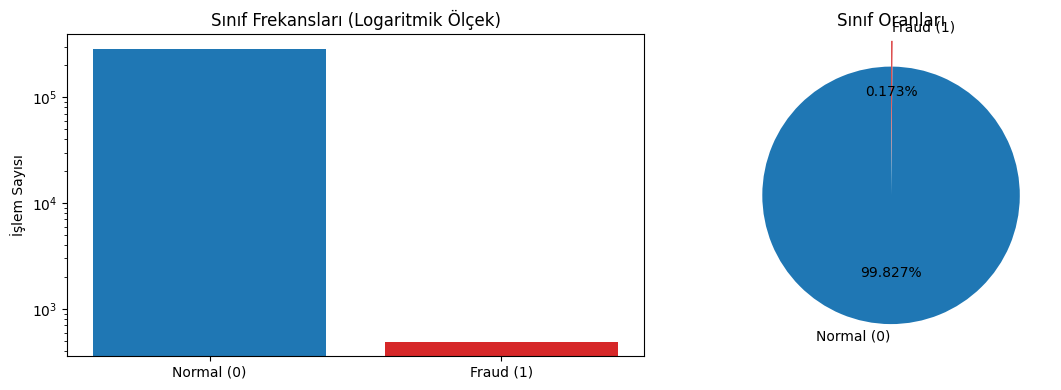

In [5]:
# 3. HEDEF DEĞİŞKEN (Class) ANALİZİ - SINIF DENGESİZLİĞİ
class_counts = fraud_data["Class"].value_counts()
class_percentages = fraud_data["Class"].value_counts(normalize=True) * 100

print("\n--- Sınıf Dağılımı ---")
print(pd.DataFrame({"Sayı": class_counts, "Yüzde (%)": class_percentages}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# Bar Grafik
bars = ax[0].bar(["Normal (0)", "Fraud (1)"], class_counts, color=["#1f77b4", "#d62728"])
ax[0].set_title("Sınıf Frekansları (Logaritmik Ölçek)")
ax[0].set_yscale("log")
ax[0].set_ylabel("İşlem Sayısı")

# Pasta Grafiği
ax[1].pie(
    class_counts,
    labels=["Normal (0)", "Fraud (1)"],
    autopct="%1.3f%%",
    colors=["#1f77b4", "#d62728"],
    explode=(0, 0.2),
    startangle=90,
)
ax[1].set_title("Sınıf Oranları")
plt.tight_layout()
plt.show()


--- İşlem Tutarı (Amount) İstatistikleri ---
Normal İşlemler:
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Dolandırıcılık İşlemleri:
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


/tmp/ipykernel_638/2521960572.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0, 1].boxplot([normal_df["Amount"], fraud_df["Amount"]], labels=["Normal (0)", "Fraud (1)"])


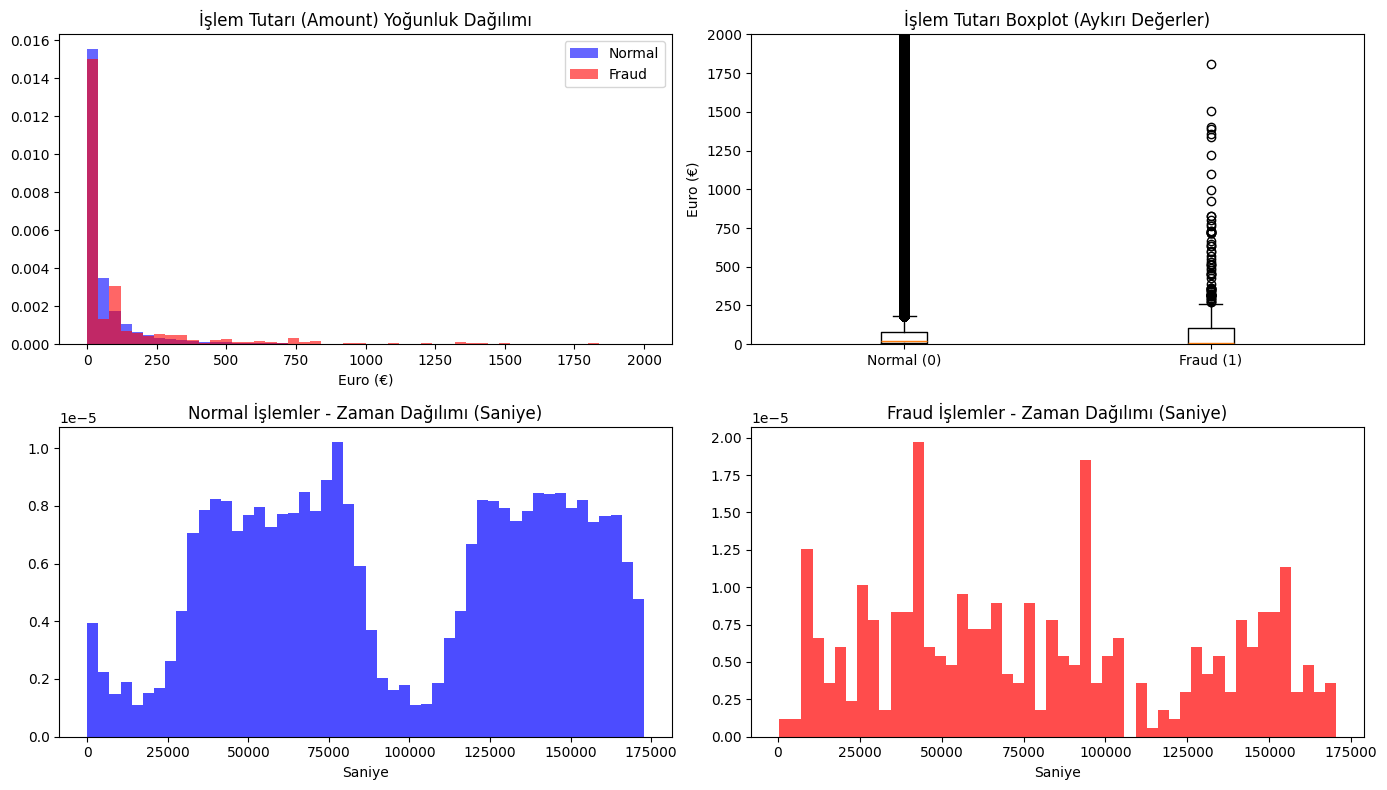

In [ ]:
# 4. 'Amount' VE 'Time' DEĞİŞKENLERİNİN İNCELENMESİ
fraud_df = fraud_data[fraud_data["Class"] == 1]
normal_df = fraud_data[fraud_data["Class"] == 0]

print("\n--- İşlem Tutarı (Amount) İstatistikleri ---")
print("Normal İşlemler:")
print(normal_df["Amount"].describe())
print("\nDolandırıcılık İşlemleri:")
print(fraud_df["Amount"].describe())

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Amount Histogram
axes[0, 0].hist(normal_df["Amount"], bins=50, range=(0, 2000), alpha=0.6, label="Normal", color="blue", density=True)
axes[0, 0].hist(fraud_df["Amount"], bins=50, range=(0, 2000), alpha=0.6, label="Fraud", color="red", density=True)
axes[0, 0].set_title("İşlem Tutarı (Amount) Yoğunluk Dağılımı")
axes[0, 0].set_xlabel("Euro (€)")
axes[0, 0].legend()

# Amount Boxplot
axes[0, 1].boxplot([normal_df["Amount"], fraud_df["Amount"]], labels=["Normal (0)", "Fraud (1)"])
axes[0, 1].set_title("İşlem Tutarı Boxplot (Aykırı Değerler)")
axes[0, 1].set_ylim([0, 2000])
axes[0, 1].set_ylabel("Euro (€)")

# Time Histogram (Normal)
axes[1, 0].hist(normal_df["Time"], bins=50, color="blue", alpha=0.7, density=True)
axes[1, 0].set_title("Normal İşlemler - Zaman Dağılımı (Saniye)")
axes[1, 0].set_xlabel("Saniye")

# Time Histogram (Fraud)
axes[1, 1].hist(fraud_df["Time"], bins=50, color="red", alpha=0.7, density=True)
axes[1, 1].set_title("Fraud İşlemler - Zaman Dağılımı (Saniye)")
axes[1, 1].set_xlabel("Saniye")

plt.tight_layout()
plt.show()


--- Class ile En Yüksek Korelasyona Sahip Özellikler ---
En Negatif Korelasyonlar:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64

En Pozitif Korelasyonlar:
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
Name: Class, dtype: float64


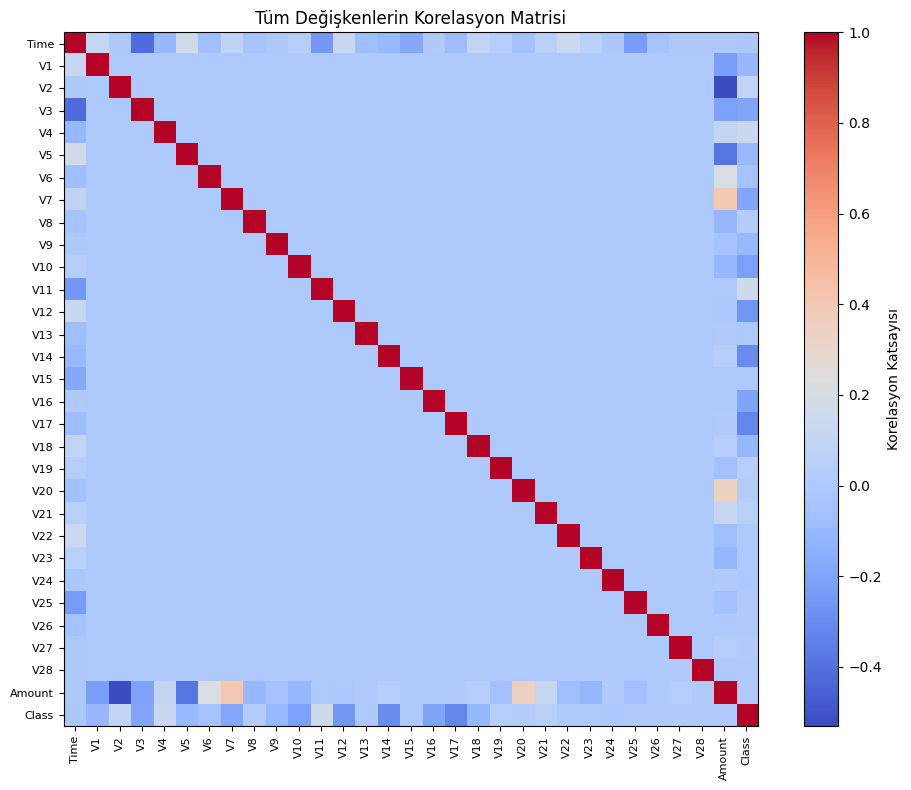

In [ ]:
# 5. KORELASYON ANALİZİ VE ISI HARİTASI (MATPLOTLIB)
corr = fraud_data.corr()
class_corr = corr["Class"].drop("Class").sort_values()

print("\n--- Class ile En Yüksek Korelasyona Sahip Özellikler ---")
print("En Negatif Korelasyonlar:")
print(class_corr.head(5))
print("\nEn Pozitif Korelasyonlar:")
print(class_corr.tail(5))

# Matplotlib ile Heatmap Oluşturma
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", interpolation="none")
plt.colorbar(label="Korelasyon Katsayısı")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=8)
plt.yticks(range(len(corr.columns)), corr.columns, fontsize=8)
plt.title("Tüm Değişkenlerin Korelasyon Matrisi", fontsize=12)
plt.tight_layout()
plt.show()


/tmp/ipykernel_638/3805999845.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[idx].boxplot([normal_df[feature], fraud_df[feature]], labels=["Normal", "Fraud"])
/tmp/ipykernel_638/3805999845.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[idx].boxplot([normal_df[feature], fraud_df[feature]], labels=["Normal", "Fraud"])
/tmp/ipykernel_638/3805999845.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[idx].boxplot([normal_df[feature], fraud_df[feature]], labels=["Normal", "Fraud"])
/tmp/ipykernel_638/3805999845.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed

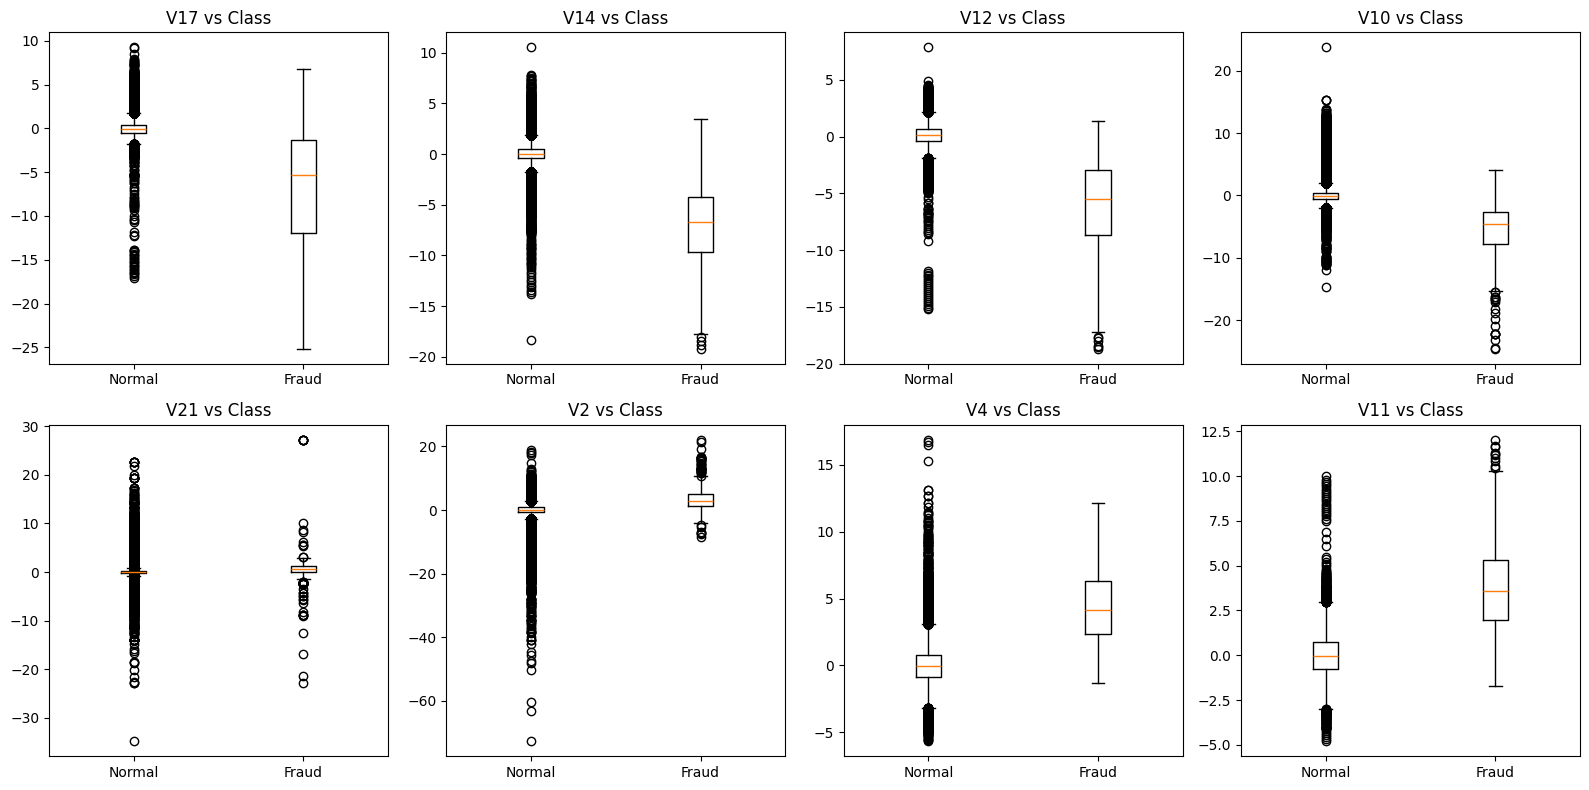

In [ ]:
# 6. EN AYIRT EDİCİ BİLEŞENLERİN (PCA) KUTU GRAFİKLERİ (BOXPLOT)
top_features = list(class_corr.head(4).index) + list(class_corr.tail(4).index)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, feature in enumerate(top_features):
    axes[idx].boxplot([normal_df[feature], fraud_df[feature]], labels=["Normal", "Fraud"])
    axes[idx].set_title(f"{feature} vs Class")

plt.tight_layout()
plt.show()

In [ ]:
#Veride Öne Çıkan Bulgular
#Aşırı Sınıf Dengesizliği:
# Hedef değişkende fraud verisi %0.172 seviyesindedir. Model eğitiminde class_weight='balanced' şeklinde seçim yapılmalıdır.
# Fraud verisi yüzde olarak çok düşük bir seviyede olduğu için standart accuracy metriği yerine Precision,recall ve F1 score gibi metrikler kullanılmalıdır.
#Tutar Karşılaştırması:
#Fraud işlemler genelde düşük tutarlarda ($0 - 300 €$ bandında) yoğunlaşmaktadır; yüksek tutarlı işlemlerde fraud oranı belirgin şekilde düşmektedir.


In [6]:
#7. Random Forest Algoritmasının Uygulanması

X = fraud_data.drop("Class",axis=1)
y =fraud_data["Class"]

#V1-V28 alanları PCA yöntemine göre standardize edilmiştir "Amount" ve "Time" alanları standardize edilir.
scaler =StandardScaler()
X["Amount"] = scaler.fit_transform(X[["Amount"]])
X["Time"] = scaler.fit_transform(X[["Time"]])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42,stratify=y)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced_subsample",max_depth=15,n_jobs=-1)
rf_model.fit(X_train, y_train)




RandomForestClassifier(class_weight='balanced_subsample', max_depth=15,
                       n_jobs=-1, random_state=42)

In [7]:
#8.Tahminlerin Yapılması
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]
# Metriklerin hesaplanması
roc_auc = roc_auc_score(y_test, y_pred_proba)
auprc = average_precision_score(y_test, y_pred_proba)

print(f"ROC-AUC Skoru : {roc_auc:.4f}")
print(f"AUPRC Skoru   : {auprc:.4f}")

ROC-AUC Skoru : 0.9657
AUPRC Skoru   : 0.8157


=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0     0.9996    0.9998    0.9997     71079
           1     0.8942    0.7561    0.8194       123

    accuracy                         0.9994     71202
   macro avg     0.9469    0.8780    0.9095     71202
weighted avg     0.9994    0.9994    0.9994     71202

ROC-AUC Skoru : 0.9657
AUPRC Skoru   : 0.8157  <-- Dengesiz verideki en kritik metrik

=== CONFUSION MATRIX ===
Doğru Normal (TN) : 71068 | Yanlış Alarm (FP) : 11
Kaçırılan Fraud (FN): 30 | Yakalanan Fraud (TP): 93


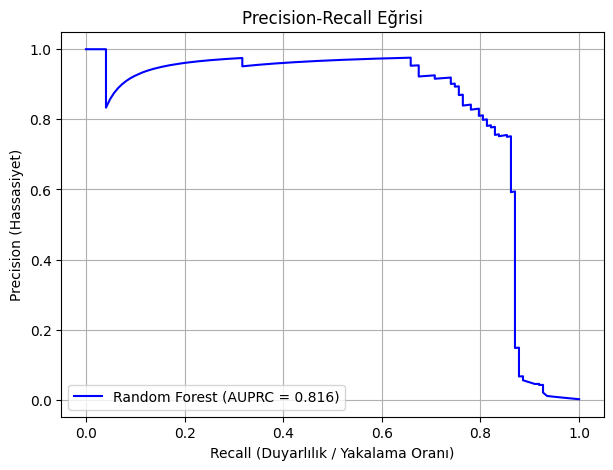

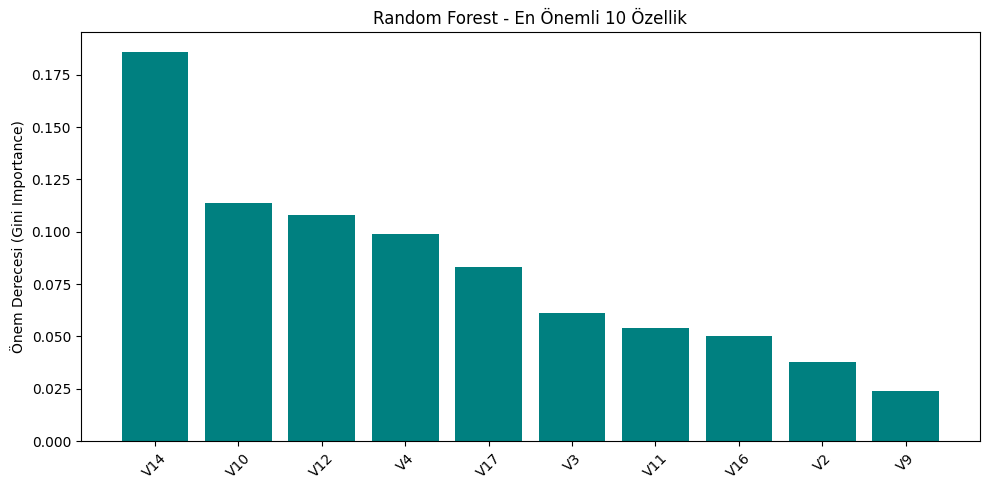

In [8]:
#9.Model Başarı Metriklerinin Değerlendirilmesi
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, digits=4))

# Metriklerin hesaplanması
roc_auc = roc_auc_score(y_test, y_pred_proba)
auprc = average_precision_score(y_test, y_pred_proba)

print(f"ROC-AUC Skoru : {roc_auc:.4f}")
print(f"AUPRC Skoru   : {auprc:.4f}  <-- Dengesiz verideki en kritik metrik")

# 6. CONFUSION MATRIX (KARMAŞIKLIK MATRİSİ)
cm = confusion_matrix(y_test, y_pred)
print("\n=== CONFUSION MATRIX ===")
print(f"Doğru Normal (TN) : {cm[0, 0]} | Yanlış Alarm (FP) : {cm[0, 1]}")
print(f"Kaçırılan Fraud (FN): {cm[1, 0]} | Yakalanan Fraud (TP): {cm[1, 1]}")

# 7. PRECISION-RECALL EĞRİSİ ÇİZİMİ
precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, color="b", label=f"Random Forest (AUPRC = {auprc:.3f})")
plt.xlabel("Recall (Duyarlılık / Yakalama Oranı)")
plt.ylabel("Precision (Hassasiyet)")
plt.title("Precision-Recall Eğrisi")
plt.legend(loc="lower left")
plt.grid(True)
plt.show()

# 8. EN ÖNEMLİ ÖZELLİKLERİN (FEATURE IMPORTANCE) GÖRSELLEŞTİRİLMESİ
importances = rf_model.feature_importances_
feature_names = X.columns
indices = np.argsort(importances)[::-1][:10]  # En önemli ilk 10 özellik

plt.figure(figsize=(10, 5))
plt.title("Random Forest - En Önemli 10 Özellik")
plt.bar(range(10), importances[indices], align="center", color="teal")
plt.xticks(range(10), [feature_names[i] for i in indices], rotation=45)
plt.ylabel("Önem Derecesi (Gini Importance)")
plt.tight_layout()
plt.show()

In [11]:
#10 Rastgele Generate Edilmiş Veri İle Model Testi

scaler_amount = StandardScaler()
scaler_time = StandardScaler()

X["Amount"] = scaler_amount.fit_transform(X[["Amount"]])
X["Time"] = scaler_time.fit_transform(X[["Time"]])




# --- YENİ ÖRNEK TAHMİN AŞAMASI ---
fraud_sample = {
    "Time": 406.0,
    "V1": -2.312227,
    "V2": 1.951992,
    "V3": -1.609851,
    "V4": 3.997906,
    "V5": -0.522188,
    "V6": -1.426545,
    "V7": -2.537387,
    "V8": 1.391657,
    "V9": -2.770089,
    "V10": -2.772272,
    "V11": 3.202033,
    "V12": -2.899907,
    "V13": -0.595222,
    "V14": -4.289254,
    "V15": 0.389724,
    "V16": -1.140747,
    "V17": -2.830056,
    "V18": -0.016822,
    "V19": 0.416956,
    "V20": 0.126911,
    "V21": 0.517232,
    "V22": -0.035049,
    "V23": -0.465211,
    "V24": 0.320198,
    "V25": 0.044519,
    "V26": 0.177840,
    "V27": 0.261145,
    "V28": -0.143375,
    "Amount": 0.00,
}

# Veriyi DataFrame yapıp sütun sırasını eşitleme
sample_df = pd.DataFrame([fraud_sample])
sample_df = sample_df[X_train.columns]

# ÖLÇEKLENDİRME (Kendi özel scaler'ları ile sadece .transform() yapılır)
sample_df["Amount"] = scaler_amount.transform(sample_df[["Amount"]])
sample_df["Time"] = scaler_time.transform(sample_df[["Time"]])

# MODEL İLE TAHMİN YAPMA (Threshold = 0.30)
CUSTOM_THRESHOLD = 0.30
fraud_probability = rf_model.predict_proba(sample_df)[:, 1][0]
is_fraud = 1 if fraud_probability >= CUSTOM_THRESHOLD else 0

# SONUÇ
print("=== YENİ ÖRNEK TAHMİN SONUCU ===")
print(f"Modelin Fraud Olma Olasılığı : %{fraud_probability * 100:.2f}")

if is_fraud == 1:
    print(
        "SONUÇ: 🚨 Bu işlem DOLANDIRICILIK (Fraud) olarak tespit edildi! Bloklanıyor..."
    )
else:
    print("SONUÇ: ✅ Bu işlem NORMAL kabul edildi.")

=== YENİ ÖRNEK TAHMİN SONUCU ===
Modelin Fraud Olma Olasılığı : %78.99
SONUÇ: 🚨 Bu işlem DOLANDIRICILIK (Fraud) olarak tespit edildi! Bloklanıyor...
